KOLOS 

# Lista 4 

In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import scipy


z rokzładów -> na procesy 
nowe narzędzia weryfikacyjne wartosc oczekiwana procesu dla slice 

#### Zadanie 1.
Kompensowany proces Poissona

1.

In [ ]:
def gen_poisson_process_1(lamb,T):
    """lamb: exponential parameter for jumps S1, S2, ... """
    t=0
    I=0
    S = []
    while t<T:
        temp = np.random.random()
        t  = t - 1/lamb * np.log(temp)
        if t > T:
            break 
        S.append(t)
    return S

def generate_poisson_jumps(lamb, T):
    """Method 2: Generates jump moments using Poisson count and Uniform distribution."""
    n = np.random.poisson(lamb * T)
    if n > 0:
        # Uniform distribution on [0, T] sorted gives the jump times
        return np.sort(np.random.uniform(0, T, n))
    return np.array([])

a= np.array(gen_poisson_process_1(2,15))
b=np.array(generate_poisson_jumps(2,15))

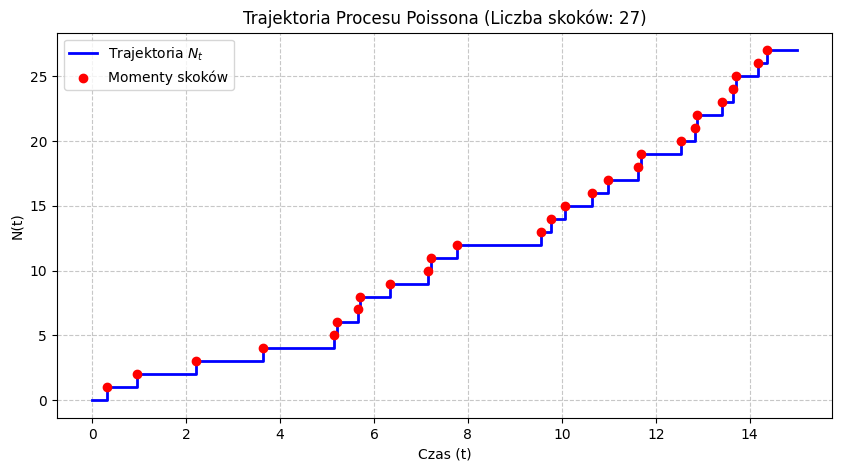

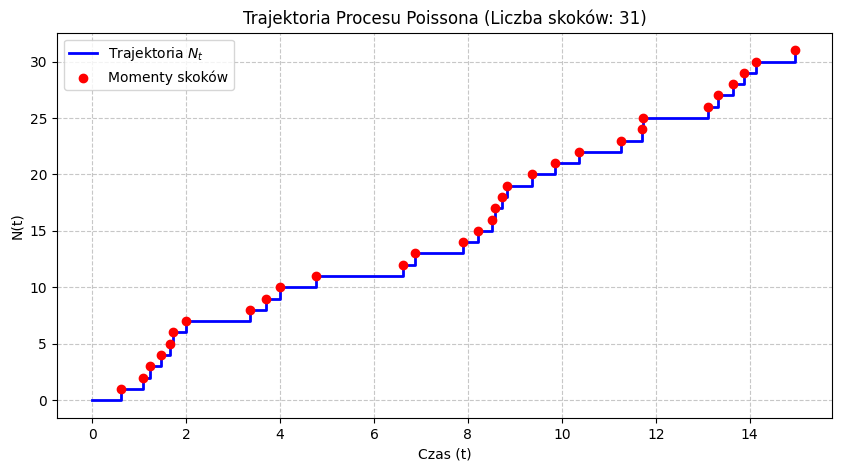

In [3]:
def plot_poisson(S, T):

    x = np.concatenate(([0], S, [T]))
    y = np.concatenate(([0], np.arange(1, len(S) + 1), [len(S)]))

    plt.figure(figsize=(10, 5))
    
    # 'where=post' -CADLAG
    plt.step(x, y, where='post', label='Trajektoria $N_t$', color='blue', linewidth=2)
    
    # points in jump places
    plt.scatter(S, np.arange(1, len(S) + 1), color='red', zorder=3, label='Momenty skoków')

    plt.title(f"Trajektoria Procesu Poissona (Liczba skoków: {len(S)})")
    plt.xlabel("Czas (t)")
    plt.ylabel("N(t)")
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.legend()
    plt.show()

plot_poisson(a, 15)
plot_poisson(b,15)


2. 

In [ ]:
def get_poisson_value(jumps, t):
    """
    Returns N(t). 
    vectorized equivalent of binary search.
    """
    return np.searchsorted(jumps, t, side='right') 

print(get_poisson_value(b, 12))

25


3. 

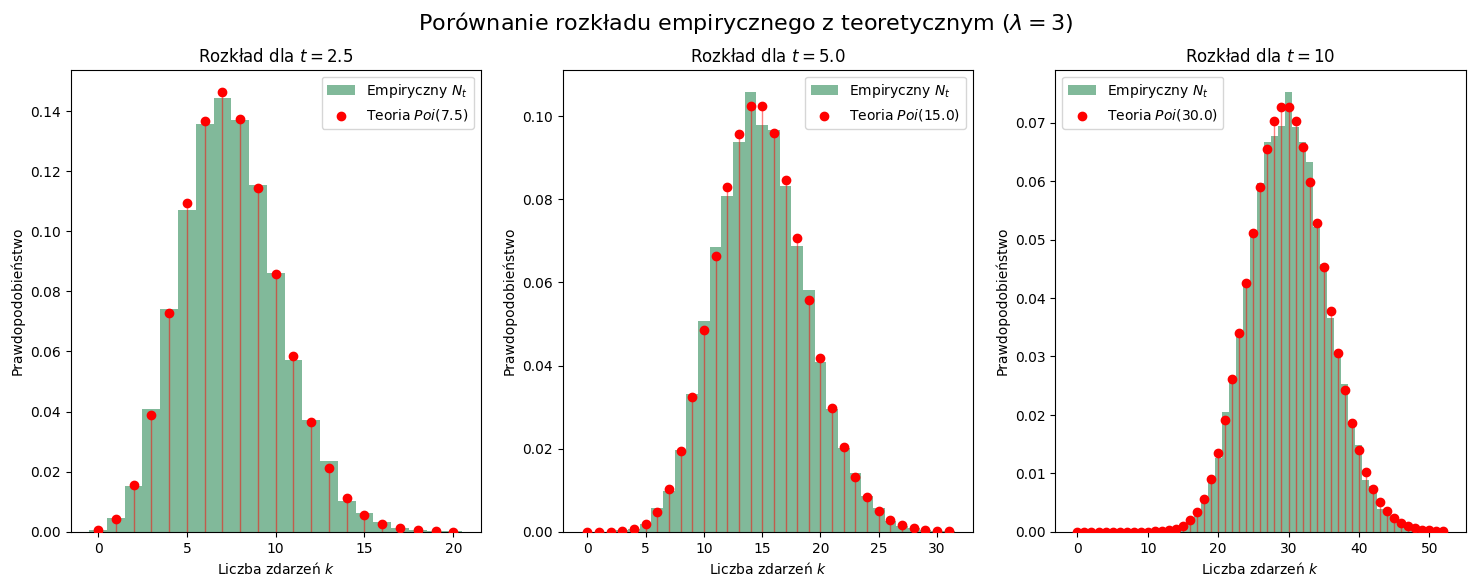

In [ ]:
def run_simulation(lamb, T, t_checkpoints, num_sims=10000):
    # Dict for samples
    samples = {t: [] for t in t_checkpoints}
    
    for _ in range(num_sims):
        S = generate_poisson_jumps(lamb, T)
        
        # what happend in t moments
        for t in t_checkpoints:
            nt_val = get_poisson_value(S, t)
            samples[t].append(nt_val)
            
    return samples

# parameters
lamb = 3
T = 10
t_points = [T/4, T/2, T]
iterations = 20000


results = run_simulation(lamb, T, t_points, iterations)

# Visualization
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for i, t in enumerate(t_points):
    data = results[t]
    ax = axes[i]
    
    # theoretical
    expected_lambda = lamb * t
    
    # Histogram
    bins = np.arange(0, np.max(data) + 2) - 0.5
    ax.hist(data, bins=bins, density=True, alpha=0.6, color='seagreen', label='Empiryczny $N_t$')
    
    x_axis = np.arange(0, np.max(data) + 1)
    y_theory = scipy.stats.poisson.pmf(x_axis, expected_lambda)
    ax.scatter(x_axis, y_theory, color='red', zorder=3, label=f'Teoria $Poi({expected_lambda:.1f})$')
    ax.vlines(x_axis, 0, y_theory, colors='red', lw=1, alpha=0.5)
    
    ax.set_title(f"Rozkład dla $t = {t}$")
    ax.set_xlabel("Liczba zdarzeń $k$")
    ax.set_ylabel("Prawdopodobieństwo")
    ax.legend()

plt.suptitle(f"Porównanie rozkładu empirycznego z teoretycznym ($\\lambda={lamb}$)", fontsize=16)
#plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

4. 

In [6]:
lamb = 3
T = 10
t_points = [T/4, T/2, T]
iterations = 200000

def empirical_mean_var(lamb,T,t_points, iterations):
    poisson_data = run_simulation(lamb, T, t_points, iterations)

    for t in t_points:
        data = poisson_data[t]
        empirical_mean = np.mean(data)
        empirical_variance = np.var(data)
        print(f"Wariancja i średnia liczby zdarzeń które się pojawiły do czasu {t}:")
        print(f"teoretyczna średnia: {(lamb*t)}, średnia empiryczna: {empirical_mean}")
        print(f"teoretyczna wariancja: {lamb*t}, wariancja empiryczna: {empirical_variance}")
        print("")
    return None

empirical_mean_var(lamb,T,t_points, iterations)


Wariancja i średnia liczby zdarzeń które się pojawiły do czasu 2.5:
teoretyczna średnia: 7.5, średnia empiryczna: 7.50133
teoretyczna wariancja: 7.5, wariancja empiryczna: 7.4709482311

Wariancja i średnia liczby zdarzeń które się pojawiły do czasu 5.0:
teoretyczna średnia: 15.0, średnia empiryczna: 14.987265
teoretyczna wariancja: 15.0, wariancja empiryczna: 15.055212819774999

Wariancja i średnia liczby zdarzeń które się pojawiły do czasu 10:
teoretyczna średnia: 30, średnia empiryczna: 29.98671
teoretyczna wariancja: 30, wariancja empiryczna: 30.223453375900007



# Zadanie 2 
Kompensowany proces poissona 

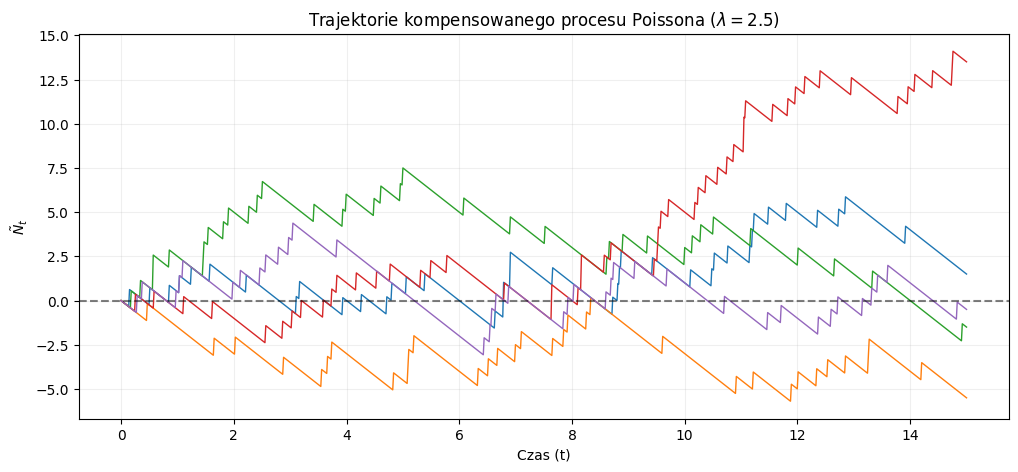

In [ ]:


def get_compensated_value(jumps, lamb, t):
    """Returns the value of the compensated process: N(t) - lambda * t
        works for t as float or np vector"""
    return get_poisson_value(jumps, t) - lamb * t

def plot_compensated_trajectories(lamb, T, num_paths=5):
    t_grid = np.linspace(0, T, 1000)
    plt.figure(figsize=(12, 5))
    
    for _ in range(num_paths):
        jumps = generate_poisson_jumps(lamb, T)
        # Vectorized call: get_poisson_value handles the whole t_grid at once
        path = get_compensated_value(jumps, lamb, t_grid)
        plt.plot(t_grid, path, linewidth=1)
        
    plt.axhline(0, color='black', linestyle='--', alpha=0.5)
    plt.title(f"Trajektorie kompensowanego procesu Poissona ($\\lambda={lamb}$)")
    plt.xlabel("Czas (t)")
    plt.ylabel("$\\~{N}_t$")
    plt.grid(True, alpha=0.2)
    plt.show()

plot_compensated_trajectories(lamb=2.5, T=15)


In [8]:
def estimate_moments(lamb, T, num_sims=20000):
    checkpoints = np.linspace(0, T, 11)
    results_matrix = np.zeros((num_sims, len(checkpoints)))
    
    for i in range(num_sims):
        jumps = generate_poisson_jumps(lamb, T)
        results_matrix[i, :] = get_compensated_value(jumps, lamb, checkpoints)
        
    means = np.mean(results_matrix, axis=0)
    variances = np.var(results_matrix, axis=0)
    
    print(f"{'t':>5} | {'Mean (Emp)':>10} | {'Mean (Theo)':>10} | {'Var (Emp)':>10} | {'Var (Theo)':>10}")
    print("-" * 65)
    for i, t in enumerate(checkpoints):
        print(f"{t:5.1f} | {means[i]:10.4f} | {0.0:10.1f} | {variances[i]:10.4f} | {lamb*t:10.1f}")

estimate_moments(2.5, 20)

    t | Mean (Emp) | Mean (Theo) |  Var (Emp) | Var (Theo)
-----------------------------------------------------------------
  0.0 |     0.0000 |        0.0 |     0.0000 |        0.0
  2.0 |    -0.0221 |        0.0 |     5.0155 |        5.0
  4.0 |    -0.0283 |        0.0 |    10.0559 |       10.0
  6.0 |    -0.0351 |        0.0 |    14.9419 |       15.0
  8.0 |    -0.0425 |        0.0 |    20.1034 |       20.0
 10.0 |    -0.0455 |        0.0 |    25.0244 |       25.0
 12.0 |    -0.0591 |        0.0 |    30.1330 |       30.0
 14.0 |    -0.0574 |        0.0 |    35.1706 |       35.0
 16.0 |    -0.0746 |        0.0 |    40.0403 |       40.0
 18.0 |    -0.0847 |        0.0 |    45.0264 |       45.0
 20.0 |    -0.1041 |        0.0 |    49.8923 |       50.0


In [ ]:
def check_martingale_property(lamb, T, s, t, num_sims=300000):
    n_s_values = []
    n_t_values = []
    
    for _ in range(num_sims):
        jumps = generate_poisson_jumps(lamb, T)
        n_s_values.append(get_compensated_value(jumps, lamb, s))
        n_t_values.append(get_compensated_value(jumps, lamb, t))
        
    n_s_values = np.array(n_s_values)
    n_t_values = np.array(n_t_values)
    
    # Round to avoid floating point issues during grouping
    unique_states = np.unique(np.round(n_s_values, 6))
    
    print(f"\n Sprawdzenie własności martyngałowej (s={s}, t={t})")
    print(f"{'Stan Ns':>10} | {'E[Nt | Ns]':>12} | {'Różnica':>10} | {'Liczba obserwacji':>8}")
    print("-" * 50)
    
    for state in unique_states:
        mask = np.round(n_s_values, 6) == state
        count = np.sum(mask)
        if count > 300: # Show only significant groups
            expected_nt = np.mean(n_t_values[mask])
            print(f"{state:10.4f} | {expected_nt:12.4f} | {abs(state-expected_nt):10.4f} | {count:8d}")
lamb =2.5
T = 20
s=5
t =15
check_martingale_property(2.5, 20, 5.0, 15.0)


 Sprawdzenie własności martyngałowej (s=5.0, t=15.0)
   Stan Ns |   E[Nt | Ns] |    Różnica | Liczba obserwacji
--------------------------------------------------
   -9.5000 |      -9.0176 |     0.4824 |      369
   -8.5000 |      -8.3546 |     0.1454 |     1121
   -7.5000 |      -7.4108 |     0.0892 |     2835
   -6.5000 |      -6.5360 |     0.0360 |     5889
   -5.5000 |      -5.5003 |     0.0003 |    10576
   -4.5000 |      -4.5565 |     0.0565 |    16468
   -3.5000 |      -3.5413 |     0.0413 |    22833
   -2.5000 |      -2.4791 |     0.0209 |    28688
   -1.5000 |      -1.5241 |     0.0241 |    33012
   -0.5000 |      -0.4783 |     0.0217 |    33700
    0.5000 |       0.5517 |     0.0517 |    33081
    1.5000 |       1.4768 |     0.0232 |    28962
    2.5000 |       2.4782 |     0.0218 |    24488
    3.5000 |       3.4650 |     0.0350 |    18808
    4.5000 |       4.4142 |     0.0858 |    13827
    5.5000 |       5.6197 |     0.1197 |     9703
    6.5000 |       6.5600 |     0.06

Rzeczywiście jest to martyngał. Jeśli chcemy zgadnąć jego wartość w przyszłości celujmy w obecną wartość.

# Zadanie 3. 

In [10]:
def poisson_gen_uni(size, lamb):
    L = np.full(size, np.power(np.e, -lamb))
    P =np.full(size, 1, dtype=float)
    k=np.full(size,0)

    mask = P > L
    while np.any(mask):
        active_count = np.sum(mask)
        random_values = np.random.uniform(0,1, size=active_count)
        P[mask] *= random_values
        k[mask] += 1
        mask = P > L
    return k - 1

#poisson_sample= poisson_gen_uni(1000000,40)

def poisson_gen_gamma(size, lamb):
    k = int(lamb - 2 * np.sqrt(lamb))
    if k < 1: k = int(lamb)
    s_k = np.random.gamma(k, 1/lamb, size=size)

    results = np.zeros(size, dtype=int)

    mask_early = s_k <= 1
    if np.any(mask_early):
        remaining_lamb = lamb * (1-s_k[mask_early])
        results[mask_early] = k + poisson_gen_uni(np.sum(mask_early), remaining_lamb)
    mask_late = ~mask_early
    if np.any(mask_late):
        results[mask_late] = np.random.binomial(k - 1, 1.0 / s_k[mask_late])

    return results 

def poisson_gen_(size, lamb):
    if lamb > 40:
        return poisson_gen_gamma(size, lamb)
    else:
        return poisson_gen_uni(size, lamb)
a = poisson_gen_gamma(10000, 100)

print(a.var(), a.mean())


98.99744375 100.2075


In [11]:
a = poisson_gen_uni(10000, 100)

print(a.var(), a.mean())


100.72724704 99.9536


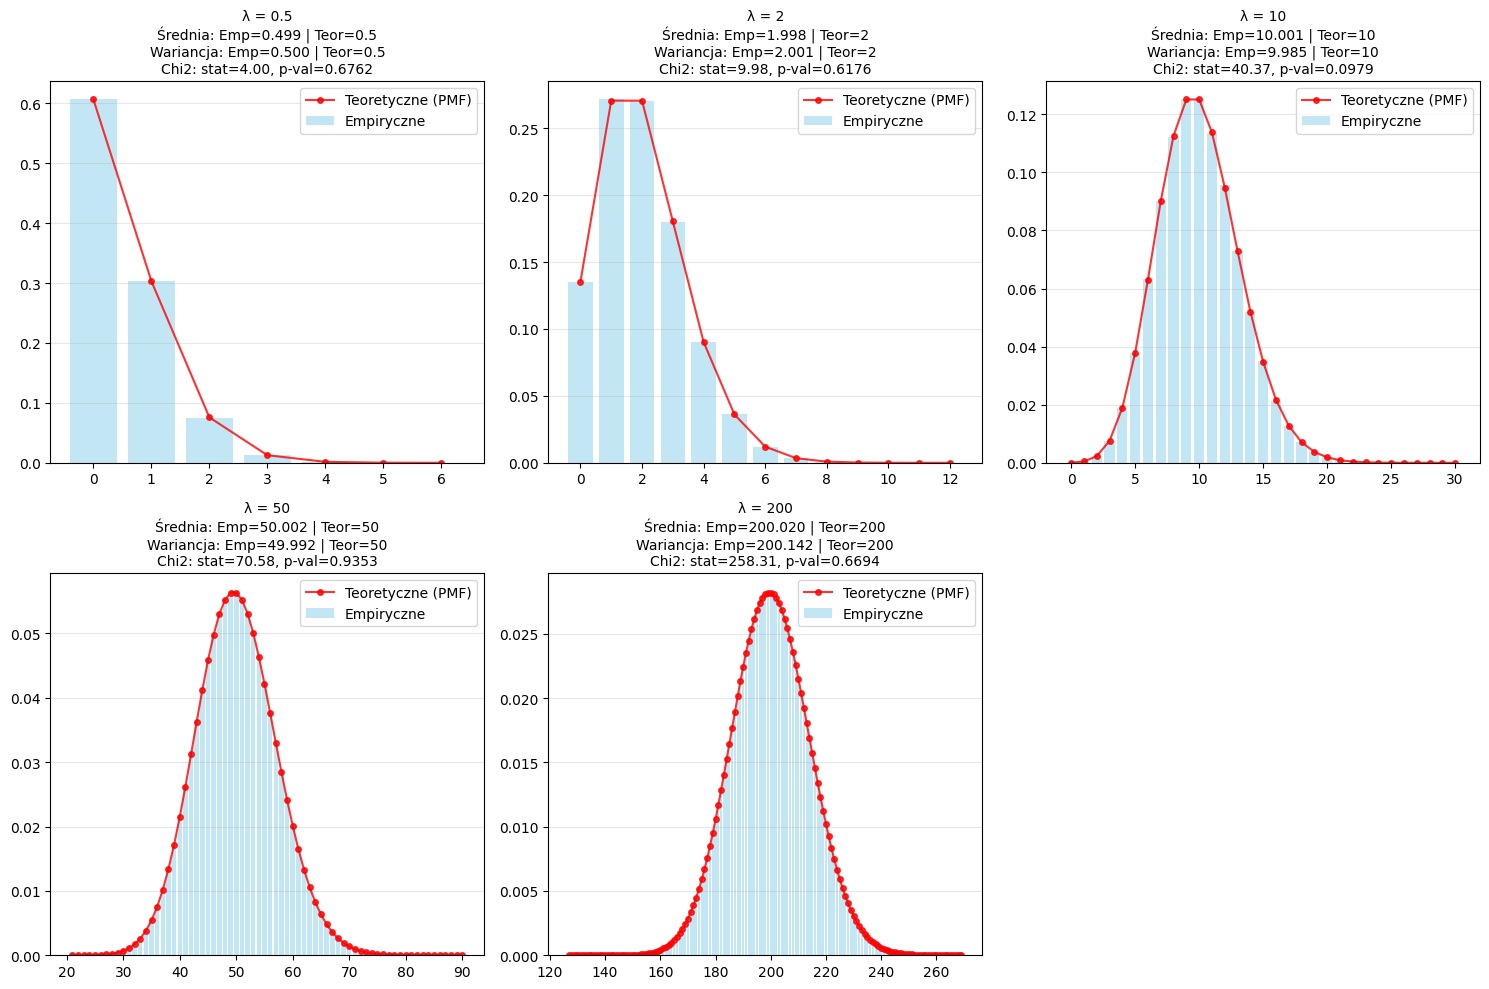

In [19]:
from scipy.stats import poisson, chisquare

lambdas = [0.5, 2, 10, 50, 200]
size = 1000000

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i, lamb in enumerate(lambdas):
    ax = axes[i]
    
    
    sample = poisson_gen_(size, lamb)
    
    
    k_vals, counts = np.unique(sample, return_counts=True)
    empirical_probs = counts / size
    
    ax.bar(k_vals, empirical_probs, alpha=0.5, color='skyblue', label='Empiryczne')
    

    x_teor = np.arange(min(k_vals), max(k_vals) + 1)
    y_teor = poisson.pmf(x_teor, lamb)
    ax.plot(x_teor, y_teor, 'ro-', alpha=0.8, markersize=4, label='Teoretyczne (PMF)')
    
    
    mean_emp = np.mean(sample)
    var_emp = np.var(sample, ddof=0)
    
    
    observed = np.bincount(sample)
    
   
    expected_probs = poisson.pmf(np.arange(len(observed)), lamb)
    expected = expected_probs * size
    
    # we put rest of the probability into the last bin
    expected[-1] += (1.0 - np.sum(expected_probs)) * size
    
    chi2_stat, p_val = chisquare(f_obs=observed, f_exp=expected)
    
    
    title = (f"λ = {lamb}\n"
             f"Średnia: Emp={mean_emp:.3f} | Teor={lamb}\n"
             f"Wariancja: Emp={var_emp:.3f} | Teor={lamb}\n"
             f"Chi2: stat={chi2_stat:.2f}, p-val={p_val:.4f}")
    
    ax.set_title(title, fontsize=10)
    ax.legend()
    ax.grid(axis='y', alpha=0.3)

# Delate the 6th plot
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()